In [6]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

Matplotlib is building the font cache; this may take a moment.


In [2]:
df = pd.read_csv('../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# count customers by contract and churn status
contract_churn = pd.crosstab(
    df['Contract'],
    df['Churn'],
)

contract_churn

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


In [4]:
contract_churn_rate = (
    df.groupby("Contract")['Churn']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .reset_index(name='ChurnRate')
)

contract_churn_rate

,Contract,ChurnRate
0,Month-to-month,42.709677
1,One year,11.269518
2,Two year,2.831858


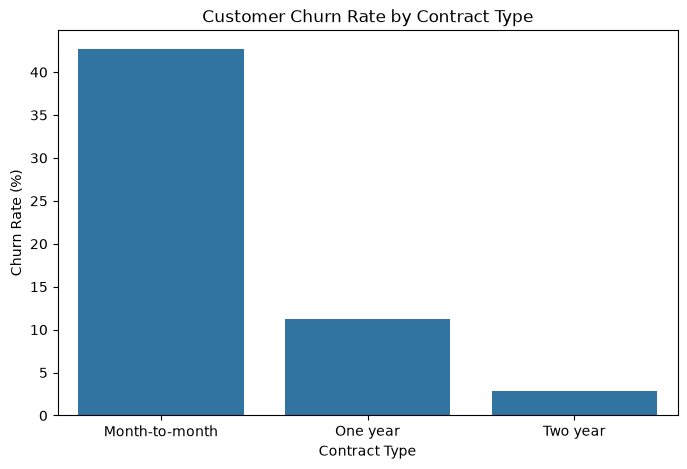

In [7]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=contract_churn_rate,
    x="Contract",
    y="ChurnRate"
)

plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

plt.show()

In [8]:
df["tenure_group"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=[
        "0-12 months",
        "13-24 months",
        "25-48 months",
        "49-72 months"
    ]
)

In [9]:
tenure_churn_rate = (
    df.groupby("tenure_group", observed=False)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="ChurnRate")
)

tenure_churn_rate

,tenure_group,ChurnRate
0,0-12 months,47.438243
1,13-24 months,28.710938
2,25-48 months,20.388959
3,49-72 months,9.513176


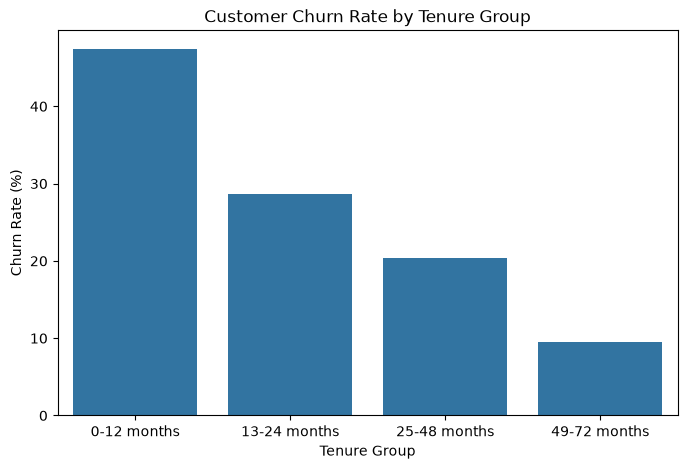

In [10]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=tenure_churn_rate,
    x="tenure_group",
    y="ChurnRate"
)

plt.title("Customer Churn Rate by Tenure Group")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")

plt.show()

In [11]:
payment_churn_rate = (
    df.groupby("PaymentMethod")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="ChurnRate")
    .sort_values("ChurnRate", ascending=False)
)

payment_churn_rate

,PaymentMethod,ChurnRate
2,Electronic check,45.285412
3,Mailed check,19.106700
0,Bank transfer (automatic),16.709845
1,Credit card (automatic),15.243101


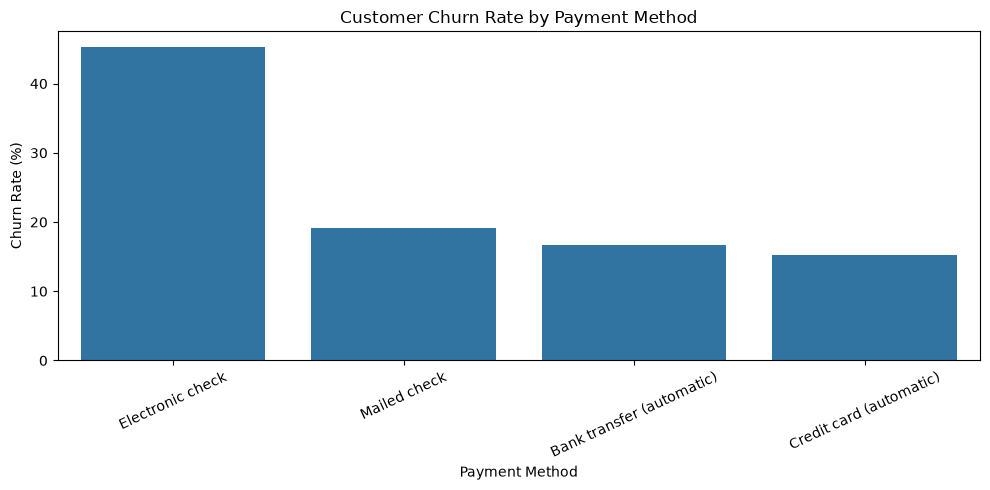

In [12]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=payment_churn_rate,
    x="PaymentMethod",
    y="ChurnRate"
)

plt.title("Customer Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [13]:
df.groupby("Churn")["MonthlyCharges"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,61.265124,31.092648,18.25,25.10,64.425,88.4,118.75
Yes,1869.0,74.441332,24.666053,18.85,56.15,79.650,94.2,118.35


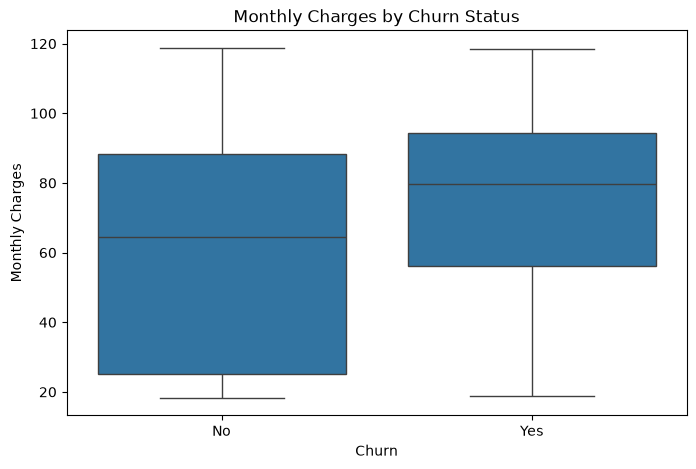

In [14]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

In [15]:
df.groupby("Churn")["MonthlyCharges"].mean()

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64

In [16]:
internet_churn_rate = (
    df.groupby("InternetService")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="ChurnRate")
    .sort_values("ChurnRate", ascending=False)
)

internet_churn_rate

,InternetService,ChurnRate
1,Fiber optic,41.892765
0,DSL,18.959108
2,No,7.404980


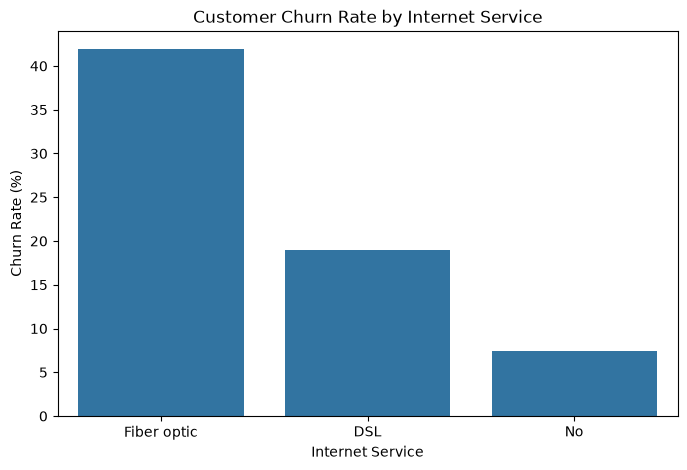

In [17]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=internet_churn_rate,
    x="InternetService",
    y="ChurnRate"
)

plt.title("Customer Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")

plt.show()

In [18]:
df.groupby("InternetService")["MonthlyCharges"].mean()

InternetService
DSL            58.102169
Fiber optic    91.500129
No             21.079194
Name: MonthlyCharges, dtype: float64

In [19]:
from scipy.stats import chi2_contingency

# Create contingency table
contract_churn_table = pd.crosstab(
    df["Contract"],
    df["Churn"]
)

contract_churn_table

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


In [20]:
# Chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    contract_churn_table
)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)

Chi-square statistic: 1184.5965720837926
P-value: 5.863038300673393e-258
Degrees of freedom: 2


In [21]:
payment_churn_table = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"]
)

payment_churn_table

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),1286,258
Credit card (automatic),1290,232
Electronic check,1294,1071
Mailed check,1304,308


In [22]:
from scipy.stats import chi2_contingency

chi2_payment, p_payment, dof_payment, expected_payment = (
    chi2_contingency(payment_churn_table)
)

print("Chi-square statistic:", chi2_payment)
print("P-value:", p_payment)
print("Degrees of freedom:", dof_payment)

Chi-square statistic: 648.1423274814
P-value: 3.6823546520098007e-140
Degrees of freedom: 3


In [23]:
alpha = 0.05

if p_payment < alpha:
    print("Reject the null hypothesis.")
    print("Payment method and churn are statistically associated.")
else:
    print("Fail to reject the null hypothesis.")
    print("Insufficient evidence of an association.")

Reject the null hypothesis.
Payment method and churn are statistically associated.


In [24]:
from scipy.stats import ttest_ind

# Separate monthly charges by churn status
charges_stayed = df.loc[
    df["Churn"] == "No",
    "MonthlyCharges"
]

charges_churned = df.loc[
    df["Churn"] == "Yes",
    "MonthlyCharges"
]

# Welch's two-sample t-test
t_stat, p_value = ttest_ind(
    charges_stayed,
    charges_churned,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: -18.407526676414673
P-value: 8.592449331547065e-73


In [25]:
alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis.")
    print("Mean monthly charges differ significantly.")
else:
    print("Fail to reject the null hypothesis.")
    print("Insufficient evidence of a difference.")

Reject the null hypothesis.
Mean monthly charges differ significantly.


In [26]:
# Separate tenure by churn status
tenure_stayed = df.loc[
    df["Churn"] == "No",
    "tenure"
]

tenure_churned = df.loc[
    df["Churn"] == "Yes",
    "tenure"
]

# Welch's two-sample t-test
t_stat_tenure, p_value_tenure = ttest_ind(
    tenure_stayed,
    tenure_churned,
    equal_var=False
)

print("T-statistic:", t_stat_tenure)
print("P-value:", p_value_tenure)

T-statistic: 34.823818696312976
P-value: 1.1954945472605766e-232


In [27]:
alpha = 0.05

if p_value_tenure < alpha:
    print("Reject the null hypothesis.")
    print("Mean tenure differs significantly between groups.")
else:
    print("Fail to reject the null hypothesis.")
    print("Insufficient evidence of a difference.")

Reject the null hypothesis.
Mean tenure differs significantly between groups.


In [28]:
print("Mean tenure - Stayed:", tenure_stayed.mean())
print("Mean tenure - Churned:", tenure_churned.mean())

Mean tenure - Stayed: 37.56996521066873
Mean tenure - Churned: 17.979133226324237


### Feature Engineering

In [29]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

df["TotalCharges"].isna().sum()

np.int64(11)

In [30]:
df.loc[
    df["TotalCharges"].isna(),
    "TotalCharges"
] = 0

In [31]:
df["TotalCharges"].isna().sum()

np.int64(0)

In [32]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   customerID        7043 non-null   str     
 1   gender            7043 non-null   str     
 2   SeniorCitizen     7043 non-null   int64   
 3   Partner           7043 non-null   str     
 4   Dependents        7043 non-null   str     
 5   tenure            7043 non-null   int64   
 6   PhoneService      7043 non-null   str     
 7   MultipleLines     7043 non-null   str     
 8   InternetService   7043 non-null   str     
 9   OnlineSecurity    7043 non-null   str     
 10  OnlineBackup      7043 non-null   str     
 11  DeviceProtection  7043 non-null   str     
 12  TechSupport       7043 non-null   str     
 13  StreamingTV       7043 non-null   str     
 14  StreamingMovies   7043 non-null   str     
 15  Contract          7043 non-null   str     
 16  PaperlessBilling  7043 non-null   s

In [33]:
# Create a copy for machine learning preparation
df_model = df.copy()

df_model.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,tenure_group
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0-12 months
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,25-48 months
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,0-12 months
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,25-48 months
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,0-12 months


In [34]:
df_model["Churn"] = df_model["Churn"].map({
    "Yes": 1,
    "No": 0
})

df_model["Churn"].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

In [35]:
df_model = df_model.drop(
    columns=["customerID"]
)

df_model.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,tenure_group
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,0-12 months
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,...,No,No,No,One year,No,Mailed check,56.95,1889.50,0,25-48 months
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,0-12 months
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0,25-48 months
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1,0-12 months


In [36]:
df_model.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   gender            7043 non-null   str     
 1   SeniorCitizen     7043 non-null   int64   
 2   Partner           7043 non-null   str     
 3   Dependents        7043 non-null   str     
 4   tenure            7043 non-null   int64   
 5   PhoneService      7043 non-null   str     
 6   MultipleLines     7043 non-null   str     
 7   InternetService   7043 non-null   str     
 8   OnlineSecurity    7043 non-null   str     
 9   OnlineBackup      7043 non-null   str     
 10  DeviceProtection  7043 non-null   str     
 11  TechSupport       7043 non-null   str     
 12  StreamingTV       7043 non-null   str     
 13  StreamingMovies   7043 non-null   str     
 14  Contract          7043 non-null   str     
 15  PaperlessBilling  7043 non-null   str     
 16  PaymentMethod     7043 non-null   s

In [37]:
# Define features
X = df_model.drop(columns=["Churn"])

# Define target
y = df_model["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7043, 20)
Target shape: (7043,)


In [38]:
# Identify categorical columns
categorical_features = X.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

# Identify numerical columns
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Categorical features:", categorical_features)
print("\nNumerical features:", numerical_features)

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'tenure_group']

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [39]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5634, 20)
X_test: (1409, 20)
y_train: (5634,)
y_test: (1409,)


In [40]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

In [41]:
# Numerical preprocessing
numerical_transformer = StandardScaler()

# Categorical preprocessing
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numerical_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

In [42]:
baseline_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

In [43]:
baseline_model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['gender','SeniorCitizen','Partner',...,'MonthlyCharges','TotalCharges', 'tenure_group']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder

In [44]:
y_pred = baseline_model.predict(X_test)

y_pred[:10]

array([0, 1, 0, 0, 0, 1, 0, 0, 0, 0])

In [45]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

In [46]:
y_pred = baseline_model.predict(X_test)

y_prob = baseline_model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

Accuracy: 0.7991483321504613
Precision: 0.6531986531986532
Recall: 0.5187165775401069
F1 Score: 0.5782414307004471
ROC-AUC: 0.8422769898473222


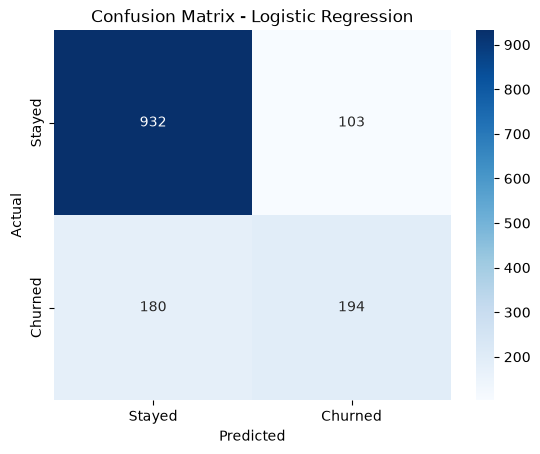

In [47]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stayed", "Churned"],
    yticklabels=["Stayed", "Churned"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [48]:
weighted_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

In [49]:
weighted_model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['gender','SeniorCitizen','Partner',...,'MonthlyCharges','TotalCharges', 'tenure_group']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder

In [50]:
y_pred_weighted = weighted_model.predict(X_test)

y_prob_weighted = weighted_model.predict_proba(X_test)[:, 1]

print(
    "Accuracy:",
    accuracy_score(y_test, y_pred_weighted)
)

print(
    "Precision:",
    precision_score(y_test, y_pred_weighted)
)

print(
    "Recall:",
    recall_score(y_test, y_pred_weighted)
)

print(
    "F1 Score:",
    f1_score(y_test, y_pred_weighted)
)

print(
    "ROC-AUC:",
    roc_auc_score(y_test, y_prob_weighted)
)

Accuracy: 0.7331440738112136
Precision: 0.4983164983164983
Recall: 0.7914438502673797
F1 Score: 0.6115702479338843
ROC-AUC: 0.8418894830659536


In [51]:
from sklearn.metrics import precision_recall_curve

# Predicted probabilities from weighted model
y_prob_weighted = weighted_model.predict_proba(X_test)[:, 1]

# Calculate precision and recall at different thresholds
precision, recall, thresholds = precision_recall_curve(
    y_test,
    y_prob_weighted
)

# Create a DataFrame for comparison
threshold_results = pd.DataFrame({
    "Threshold": thresholds,
    "Precision": precision[:-1],
    "Recall": recall[:-1]
})

threshold_results.head()

,Threshold,Precision,Recall
0,0.008797,0.265436,1.0
1,0.008883,0.265625,1.0
2,0.008885,0.265814,1.0
3,0.009047,0.266003,1.0
4,0.009512,0.266192,1.0


In [52]:
threshold_results[
    threshold_results["Threshold"].isin(
        [0.3, 0.4, 0.5, 0.6, 0.7]
    )
]

,Threshold,Precision,Recall


In [53]:
for target_threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:

    idx = (
        abs(threshold_results["Threshold"] - target_threshold)
    ).idxmin()

    row = threshold_results.loc[idx]

    print(
        f"Threshold: {row['Threshold']:.3f} | "
        f"Precision: {row['Precision']:.3f} | "
        f"Recall: {row['Recall']:.3f}"
    )

Threshold: 0.300 | Precision: 0.427 | Recall: 0.925
Threshold: 0.400 | Precision: 0.474 | Recall: 0.880
Threshold: 0.501 | Precision: 0.498 | Recall: 0.791
Threshold: 0.600 | Precision: 0.561 | Recall: 0.717
Threshold: 0.700 | Precision: 0.608 | Recall: 0.580


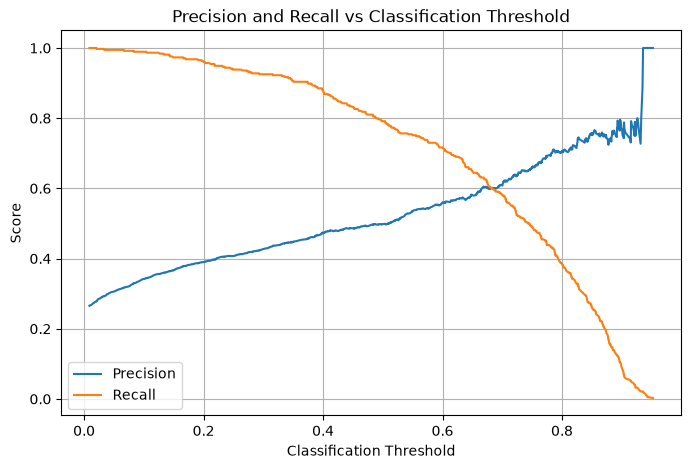

In [54]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Precision"],
    label="Precision"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Recall"],
    label="Recall"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision and Recall vs Classification Threshold")
plt.legend()
plt.grid(True)
plt.show()

In [55]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

print("Baseline Logistic Regression")
print(classification_report(y_test, y_pred))

print("Class-Weighted Logistic Regression")
print(classification_report(y_test, y_pred_weighted))

Baseline Logistic Regression
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.65      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409

Class-Weighted Logistic Regression
              precision    recall  f1-score   support

           0       0.90      0.71      0.80      1035
           1       0.50      0.79      0.61       374

    accuracy                           0.73      1409
   macro avg       0.70      0.75      0.70      1409
weighted avg       0.80      0.73      0.75      1409



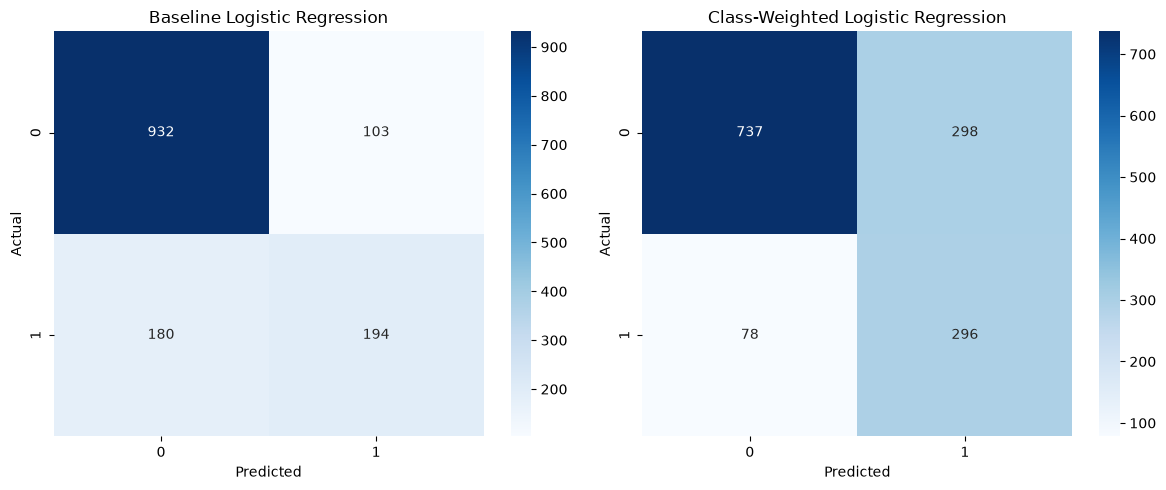

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_baseline = confusion_matrix(y_test, y_pred)
cm_weighted = confusion_matrix(y_test, y_pred_weighted)

sns.heatmap(
    cm_baseline,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Baseline Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    cm_weighted,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[1]
)
axes[1].set_title("Class-Weighted Logistic Regression")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [57]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)

y_pred_rf = random_forest_model.predict(X_test)
y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

In [58]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Random Forest Results")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))

Random Forest Results
Accuracy: 0.7672107877927609
Precision: 0.5534883720930233
Recall: 0.6363636363636364
F1 Score: 0.5920398009950248
ROC-AUC: 0.8211591619520008


In [59]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline

gradient_boosting_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

gradient_boosting_model.fit(X_train, y_train)

y_pred_gb = gradient_boosting_model.predict(X_test)
y_prob_gb = gradient_boosting_model.predict_proba(X_test)[:, 1]

In [60]:
print("Gradient Boosting Results")
print("Accuracy:", accuracy_score(y_test, y_pred_gb))
print("Precision:", precision_score(y_test, y_pred_gb))
print("Recall:", recall_score(y_test, y_pred_gb))
print("F1 Score:", f1_score(y_test, y_pred_gb))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_gb))

Gradient Boosting Results
Accuracy: 0.8026969481902059
Precision: 0.6655172413793103
Recall: 0.516042780748663
F1 Score: 0.5813253012048193
ROC-AUC: 0.8432987160608645


In [61]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Weighted Logistic Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_weighted),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_gb)
    ],
    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, y_pred_weighted),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_gb)
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, y_pred_weighted),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_gb)
    ],
    "F1": [
        f1_score(y_test, y_pred),
        f1_score(y_test, y_pred_weighted),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_gb)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob),
        roc_auc_score(y_test, y_prob_weighted),
        roc_auc_score(y_test, y_prob_rf),
        roc_auc_score(y_test, y_prob_gb)
    ]
})

model_comparison.round(3)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.799,0.653,0.519,0.578,0.842
1,Weighted Logistic Regression,0.733,0.498,0.791,0.612,0.842
2,Random Forest,0.767,0.553,0.636,0.592,0.821
3,Gradient Boosting,0.803,0.666,0.516,0.581,0.843


In [62]:
# Get the fitted preprocessing transformer
fitted_preprocessor = baseline_model.named_steps["preprocessor"]

# Get feature names after preprocessing
feature_names = fitted_preprocessor.get_feature_names_out()

# Get Logistic Regression coefficients
coefficients = baseline_model.named_steps["classifier"].coef_[0]

# Create a DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Sort by absolute coefficient magnitude
feature_importance["Abs_Coefficient"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    "Abs_Coefficient",
    ascending=False
)

feature_importance.head(15)

,Feature,Coefficient,Abs_Coefficient
1,num__tenure,-1.148180,1.148180
38,cat__Contract_Two year,-0.837689,0.837689
15,cat__InternetService_DSL,-0.650821,0.650821
16,cat__InternetService_Fiber optic,0.644949,0.644949
36,cat__Contract_Month-to-month,0.629217,0.629217
2,num__MonthlyCharges,-0.510694,0.510694
46,cat__tenure_group_13-24 months,-0.430923,0.430923
48,cat__tenure_group_49-72 months,0.387258,0.387258
39,cat__PaperlessBilling_No,-0.341150,0.341150
25,cat__DeviceProtection_No internet service,-0.295843,0.295843


In [63]:
# Remove tenure_group from the model features
X = df_model.drop(columns=["Churn", "tenure_group"])
y = df_model["Churn"]

categorical_features = X.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (5634, 19)
Testing shape: (1409, 19)


In [64]:
# Rebuild preprocessing
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numerical_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

# Logistic Regression
baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

baseline_model.fit(X_train, y_train)

y_pred = baseline_model.predict(X_test)
y_prob = baseline_model.predict_proba(X_test)[:, 1]

# Class-Weighted Logistic Regression
weighted_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

weighted_model.fit(X_train, y_train)

y_pred_weighted = weighted_model.predict(X_test)
y_prob_weighted = weighted_model.predict_proba(X_test)[:, 1]

# Gradient Boosting
gradient_boosting_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

gradient_boosting_model.fit(X_train, y_train)

y_pred_gb = gradient_boosting_model.predict(X_test)
y_prob_gb = gradient_boosting_model.predict_proba(X_test)[:, 1]

In [65]:
print("Baseline Logistic Regression")
print("F1:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

print("\nWeighted Logistic Regression")
print("F1:", f1_score(y_test, y_pred_weighted))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_weighted))

print("\nGradient Boosting")
print("F1:", f1_score(y_test, y_pred_gb))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_gb))

Baseline Logistic Regression
F1: 0.6040462427745664
ROC-AUC: 0.8421349040274871

Weighted Logistic Regression
F1: 0.6136125654450262
ROC-AUC: 0.8416388953473353

Gradient Boosting
F1: 0.5813253012048193
ROC-AUC: 0.8432754656539823


In [66]:
feature_names = (
    baseline_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

coefficients = (
    baseline_model
    .named_steps["classifier"]
    .coef_[0]
)

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

feature_importance["Abs_Coefficient"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    "Abs_Coefficient",
    ascending=False
)

feature_importance.head(15)

,Feature,Coefficient,Abs_Coefficient
1,num__tenure,-1.257539,1.257539
38,cat__Contract_Two year,-0.776594,0.776594
15,cat__InternetService_DSL,-0.648646,0.648646
16,cat__InternetService_Fiber optic,0.634195,0.634195
2,num__MonthlyCharges,-0.591863,0.591863
36,cat__Contract_Month-to-month,0.582883,0.582883
3,num__TotalCharges,0.536253,0.536253
39,cat__PaperlessBilling_No,-0.343227,0.343227
25,cat__DeviceProtection_No internet service,-0.300104,0.300104
34,cat__StreamingMovies_No internet service,-0.300104,0.300104


In [67]:
from sklearn.metrics import confusion_matrix

threshold = 0.4

y_pred_threshold = (
    y_prob_weighted >= threshold
).astype(int)

print("Threshold:", threshold)
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_threshold))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_threshold))

Threshold: 0.4
Confusion Matrix:
[[664 371]
 [ 50 324]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.64      0.76      1035
           1       0.47      0.87      0.61       374

    accuracy                           0.70      1409
   macro avg       0.70      0.75      0.68      1409
weighted avg       0.81      0.70      0.72      1409



In [68]:
# Business assumptions
campaign_cost_per_customer = 500
revenue_retained_per_customer = 5000
campaign_effectiveness = 0.20

# Confusion matrix values
tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_pred_threshold
).ravel()

customers_contacted = tp + fp
churners_identified = tp

expected_retained_customers = (
    churners_identified * campaign_effectiveness
)

campaign_cost = (
    customers_contacted * campaign_cost_per_customer
)

expected_retained_revenue = (
    expected_retained_customers
    * revenue_retained_per_customer
)

net_expected_value = (
    expected_retained_revenue
    - campaign_cost
)

print("Customers contacted:", customers_contacted)
print("Expected retained customers:", expected_retained_customers)
print("Campaign cost:", campaign_cost)
print("Expected retained revenue:", expected_retained_revenue)
print("Net expected value:", net_expected_value)

Customers contacted: 695
Expected retained customers: 64.8
Campaign cost: 347500
Expected retained revenue: 324000.0
Net expected value: -23500.0


In [69]:
import mlflow
import mlflow.sklearn

# Set the experiment name
mlflow.set_experiment("Customer Churn Prediction")

print("MLflow experiment configured!")

2026/10/30 02:05:30 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/30 02:05:30 INFO mlflow.store.db.utils: Updating database tables
2026/10/30 02:05:31 INFO mlflow.tracking.fluent: Experiment with name 'Customer Churn Prediction' does not exist. Creating a new experiment.


MLflow experiment configured!


In [70]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

with mlflow.start_run(run_name="Baseline_Logistic_Regression"):

    # Log parameters
    mlflow.log_param("model", "Logistic Regression")
    mlflow.log_param("max_iter", 1000)
    mlflow.log_param("class_weight", None)
    mlflow.log_param("threshold", 0.5)

    # Log metrics
    mlflow.log_metric("accuracy", accuracy_score(y_test, y_pred))
    mlflow.log_metric("precision", precision_score(y_test, y_pred))
    mlflow.log_metric("recall", recall_score(y_test, y_pred))
    mlflow.log_metric("f1_score", f1_score(y_test, y_pred))
    mlflow.log_metric("roc_auc", roc_auc_score(y_test, y_prob))

    # Log model artifact
    mlflow.sklearn.log_model(
        baseline_model,
        artifact_path="baseline_logistic_regression"
    )

print("Baseline model logged to MLflow!")

2026/10/30 02:05:39 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Baseline model logged to MLflow!


In [72]:
# Log Weighted Logistic Regression
with mlflow.start_run(run_name="Weighted_Logistic_Regression"):

    mlflow.log_param("model", "Logistic Regression")
    mlflow.log_param("max_iter", 1000)
    mlflow.log_param("class_weight", "balanced")
    mlflow.log_param("threshold", 0.5)

    mlflow.log_metric("accuracy", accuracy_score(y_test, y_pred_weighted))
    mlflow.log_metric("precision", precision_score(y_test, y_pred_weighted))
    mlflow.log_metric("recall", recall_score(y_test, y_pred_weighted))
    mlflow.log_metric("f1_score", f1_score(y_test, y_pred_weighted))
    mlflow.log_metric("roc_auc", roc_auc_score(y_test, y_prob_weighted))

    mlflow.sklearn.log_model(
        weighted_model,
        name="weighted_logistic_regression"
    )


# Log Gradient Boosting
with mlflow.start_run(run_name="Gradient_Boosting"):

    mlflow.log_param("model", "Gradient Boosting")
    mlflow.log_param("n_estimators", 100)
    mlflow.log_param("learning_rate", 0.1)
    mlflow.log_param("max_depth", 3)
    mlflow.log_param("threshold", 0.5)

    mlflow.log_metric("accuracy", accuracy_score(y_test, y_pred_gb))
    mlflow.log_metric("precision", precision_score(y_test, y_pred_gb))
    mlflow.log_metric("recall", recall_score(y_test, y_pred_gb))
    mlflow.log_metric("f1_score", f1_score(y_test, y_pred_gb))
    mlflow.log_metric("roc_auc", roc_auc_score(y_test, y_prob_gb))

    mlflow.sklearn.log_model(
    gradient_boosting_model,
    name="gradient_boosting",
    skops_trusted_types=["sklearn.tree._tree.Tree"]
)

print("All model experiments logged successfully!")

All model experiments logged successfully!


In [73]:
print("Tracking URI:", mlflow.get_tracking_uri())
print("Experiment:", mlflow.get_experiment_by_name("Customer Churn Prediction"))

Tracking URI: sqlite:////Users/saidattaputta/Desktop/customer-churn-prediction-analytics/notebooks/mlflow.db
Experiment: <Experiment: artifact_location='/Users/saidattaputta/Desktop/customer-churn-prediction-analytics/notebooks/mlruns/1', creation_time=1793306131097, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1793306131097, lifecycle_stage='active', name='Customer Churn Prediction', tags={}, trace_location=None, workspace='default'>


In [74]:
import joblib
from pathlib import Path

model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    weighted_model,
    model_dir / "churn_model.pkl"
)

print("Final model saved successfully!")

Final model saved successfully!
